**🛠️ Step 1: Import Libraries**

In [1]:
import os
import shutil
import random

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


**📂 Step 2: Define Dataset Path**


In [2]:

original_data_path = r"C:\Users\Admin\Desktop\binary-dataset"

split_data_path = r"C:\Users\Admin\Desktop\binary-dataset\SplitDataset"

train_path = os.path.join(split_data_path, 'train')
val_path = os.path.join(split_data_path, 'val')
test_path = os.path.join(split_data_path, 'test')

categories = ['Normal', 'Pneumonia']

for folder in [train_path, val_path, test_path]:
    os.makedirs(folder, exist_ok=True)
    for category in categories:
        os.makedirs(os.path.join(folder, category), exist_ok=True)

print("SplitDataset folder structure created successfully!")


SplitDataset folder structure created successfully!


**🖼️ Step 3: Split Dataset into Train (70%) and Test (15%) and Validation(15%)**

In [4]:
original_data_path = r"C:\Users\Admin\Desktop\binary-dataset"
split_data_path = r"C:\Users\Admin\Desktop\binary-dataset\SplitDataset"
train_split = 0.7
val_split = 0.15
test_split = 0.15

categories = ['Normal', 'Pneumonia']

for category in categories:
    category_path = os.path.join(original_data_path, category)
    all_images = os.listdir(category_path)
    all_images = [img for img in all_images if img.lower().endswith(('.jpg', '.jpeg', '.png'))]

    random.shuffle(all_images)

    total = len(all_images)
    train_count = int(train_split * total)
    val_count = int(val_split * total)
    
    train_files = all_images[:train_count]
    val_files = all_images[train_count:train_count+val_count]
    test_files = all_images[train_count+val_count:]

    def copy_files(file_list, target_folder):
        for fname in file_list:
            src = os.path.join(category_path, fname)
            dst = os.path.join(split_data_path, target_folder, category, fname)
            shutil.copy2(src, dst)

    copy_files(train_files, 'train')
    copy_files(val_files, 'val')
    copy_files(test_files, 'test')

    print(f" {category} : {len(train_files)} train, {len(val_files)} val, {len(test_files)} test")

print(" Répartition automatique terminée !")


 Normal : 7134 train, 1528 val, 1530 test
 Pneumonia : 2991 train, 640 val, 642 test
 Répartition automatique terminée !


**🖼️ Step 4: Load and Preprocess Images**

In [3]:
img_size = 150

def load_data_from_folder(base_path, categories, img_size):
    data = []
    labels = []
    for label, category in enumerate(categories): 
        folder_path = os.path.join(base_path, category)
        for filename in os.listdir(folder_path):
            if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(folder_path, filename)
                try:
                    img = load_img(img_path, color_mode='grayscale', target_size=(img_size, img_size))
                    img_array = img_to_array(img)
                    data.append(img_array)
                    labels.append(label)
                except Exception as e:
                    print(f"Erreur chargement {img_path} : {e}")
    return np.array(data, dtype='float32') / 255.0, np.array(labels)

train_dir = os.path.join(split_data_path, 'train')
val_dir = os.path.join(split_data_path, 'val')
test_dir = os.path.join(split_data_path, 'test')

X_train, y_train = load_data_from_folder(train_dir, categories, img_size)
X_val, y_val = load_data_from_folder(val_dir, categories, img_size)
X_test, y_test = load_data_from_folder(test_dir, categories, img_size)

print(" Images chargées et normalisées.")
print(f"Train : {X_train.shape}, Labels : {y_train.shape}")
print(f"Validation : {X_val.shape}")
print(f"Test : {X_test.shape}")


 Images chargées et normalisées.
Train : (13220, 150, 150, 1), Labels : (13220,)
Validation : (4039, 150, 150, 1)
Test : (4028, 150, 150, 1)


**🧠 Step 5: Build CNN Model from Scratch**

In [4]:

model = Sequential()

model.add(Conv2D(16, (3, 3), activation='relu', input_shape=(img_size, img_size, 1)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.01))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5)) 
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()


C:\Users\Admin\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 148, 148, 16)        │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 74, 74, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 72, 72, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 36, 36, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 34, 34, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 17, 17, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 15, 15, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 7, 7, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         802,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 900,225 (3.43 MB)

 Trainable params: 900,225 (3.43 MB)

 Non-trainable params: 0 (0.00 B)

**📈 Step 6: Train the CNN Model**

In [5]:
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 90s 206ms/step - accuracy: 0.8561 - loss: 0.3000 - val_accuracy: 0.9804 - val_loss: 0.0557
Epoch 2/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 85s 204ms/step - accuracy: 0.9769 - loss: 0.0669 - val_accuracy: 0.9879 - val_loss: 0.0357
Epoch 3/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 143s 206ms/step - accuracy: 0.9845 - loss: 0.0509 - val_accuracy: 0.9886 - val_loss: 0.0300
Epoch 4/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 85s 205ms/step - accuracy: 0.9880 - loss: 0.0349 - val_accuracy: 0.9906 - val_loss: 0.0246
Epoch 5/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 85s 204ms/step - accuracy: 0.9911 - loss: 0.0301 - val_accuracy: 0.9931 - val_loss: 0.0164
Epoch 6/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 85s 206ms/step - accuracy: 0.9932 - loss: 0.0214 - val_accuracy: 0.9941 - val_loss: 0.0137
Epoch 7/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 141s 204ms/step - accuracy: 0.9945 - loss: 0.0163 - val_accuracy: 0.9953 - val_loss: 0.0126
Epoch 8/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 85s 205ms/step - accuracy: 0.9966 - loss:

**✅ Step 7: Evaluate the Model**

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"\n Test Accuracy: {test_accuracy:.4f}")


126/126 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.9997 - loss: 0.0024

 Test Accuracy: 0.9988


**🔍 Step 8: Make Predictions & Classification Report**

In [7]:

y_pred_probs = model.predict(X_test)
y_pred_classes = (y_pred_probs > 0.5).astype(int)

print("\n Classification Report:\n")
print(classification_report(y_test, y_pred_classes))


126/126 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step

 Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2846
           1       1.00      1.00      1.00      1182

    accuracy                           1.00      4028
   macro avg       1.00      1.00      1.00      4028
weighted avg       1.00      1.00      1.00      4028



**🔥 Step 9: Plot Confusion Matrix**

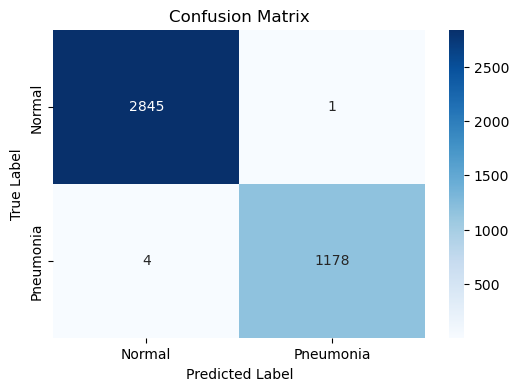

In [8]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Pneumonia"], yticklabels=["Normal", "Pneumonia"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


**📊 Step 10: Visualize Training Accuracy & Loss**

**📈 Courbe d'accuracy**

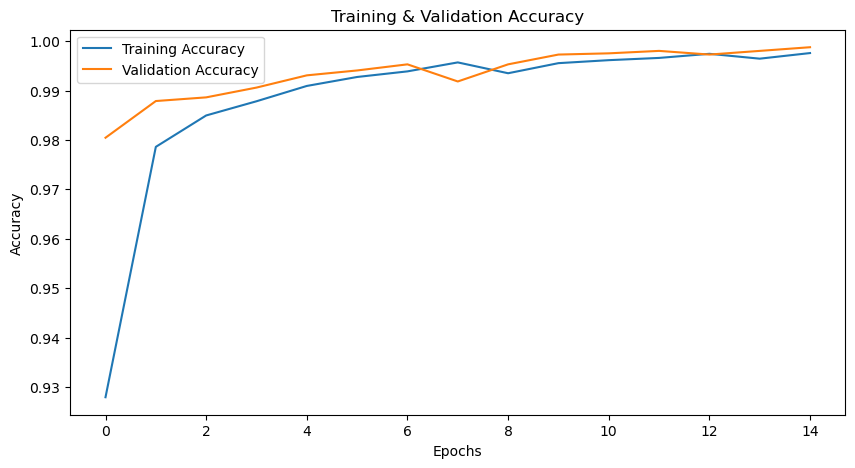

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label="Training Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy")
plt.legend()
plt.show()


**📉 Courbe de perte**

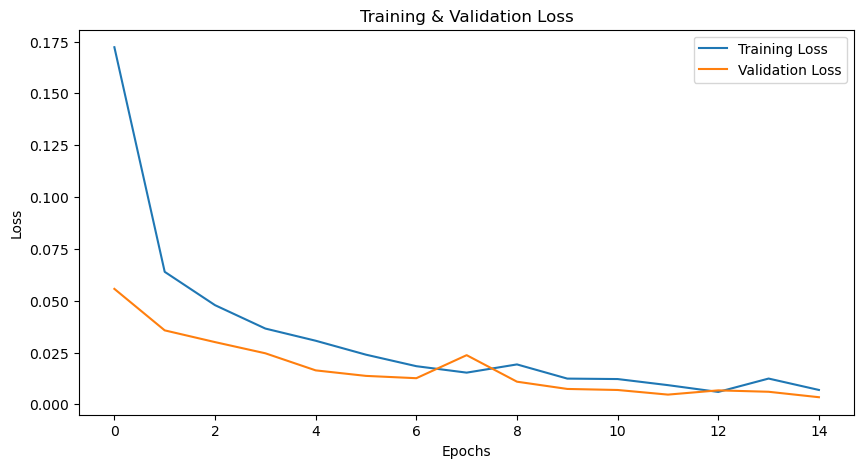

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.legend()
plt.show()


**🖼️ Step 11: Visualiser des prédictions sur des images**

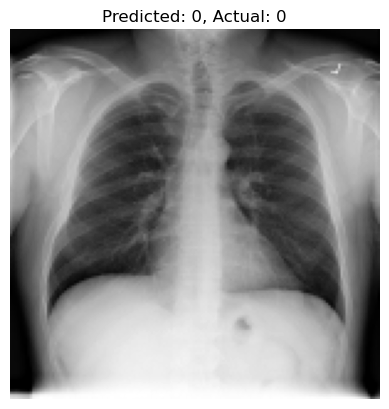

In [11]:
index = 0  
plt.imshow(X_test[index].reshape(img_size, img_size), cmap='gray')
plt.title(f"Predicted: {y_pred_classes[index][0]}, Actual: {y_test[index]}")
plt.axis('off')
plt.show()


In [12]:
model.save("cnn_pneumonia_model_binary3.h5")
print("Modèle sauvegardé")


Modèle sauvegardé
